# Lösung: YOLO26 auf Münzen trainieren

Wir trainieren YOLO26n mit **Transfer Learning**: Ausgangspunkt sind die auf COCO vortrainierten Gewichte.

Trainingsdaten sind 512 Bilder des Roboflow-Datensatzes und 78 eigene Fotos. Wir trainieren mit `imgsz=960`, weil die Münzen auf den Handyfotos klein sind. Auf einer CPU dauert eine Epoche so etwa zehn Minuten. Mit einer GPU, z. B. in Colab, geht es um ein Vielfaches schneller.

## Umgebung

Die Notebooks laufen lokal oder in Google Colab. Für Colab `use_colab = True` setzen und unter *Laufzeit > Laufzeittyp ändern* eine GPU wählen.

Die Version von `ultralytics` ist festgelegt, damit die Notebooks auch in späteren Semestern laufen.

In [1]:
use_colab = False

if use_colab:
    %pip install -q ultralytics==8.4.215
    from google.colab import drive
    drive.mount("/content/drive")
    base_path = "/content/drive/MyDrive"
else:
    # lokal einmalig installieren: pip install ultralytics==8.4.215
    base_path = ".."

import ultralytics
ultralytics.checks()

Ultralytics 8.4.215 🚀 Python-3.10.18 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
Setup complete ✅ (16 CPUs, 15.2 GB RAM, 114.8/1006.9 GB disk)


## Datensatz wählen

In [2]:
import os
from pathlib import Path

# Roboflow-Daten und eigene Fotos, siehe LösungDatensatzVorbereiten.ipynb
DATA = os.path.join(base_path, "Datensätze", "muenzen_gesamt", "data.yaml")
print(Path(DATA).exists())

EPOCHS = 50          # auf der CPU zum Ausprobieren z. B. 5

True


## Training

- `patience`: Early Stopping, wenn sich die Validierungsgüte so viele Epochen nicht verbessert
- `device`: `0` für die erste GPU, `"cpu"` für die CPU, ohne Angabe automatisch

In [3]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")          # vortrainiert auf COCO
results = model.train(
    data=DATA,
    epochs=EPOCHS,
    imgsz=960,          # gilt danach automatisch auch für predict und val
    batch=16,           # bei Speichermangel batch=8
    patience=10,
    name="muenzen",
    exist_ok=True,      # immer nach runs/detect/muenzen schreiben, nicht muenzen-2
)
run = Path(results.save_dir)
print("Ergebnisse in", run)

Ultralytics 8.4.215 🚀 Python-3.10.18 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../Datensätze/muenzen_gesamt/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=muenzen, nbs=64, nms=None, opset=

## Trainingsverlauf

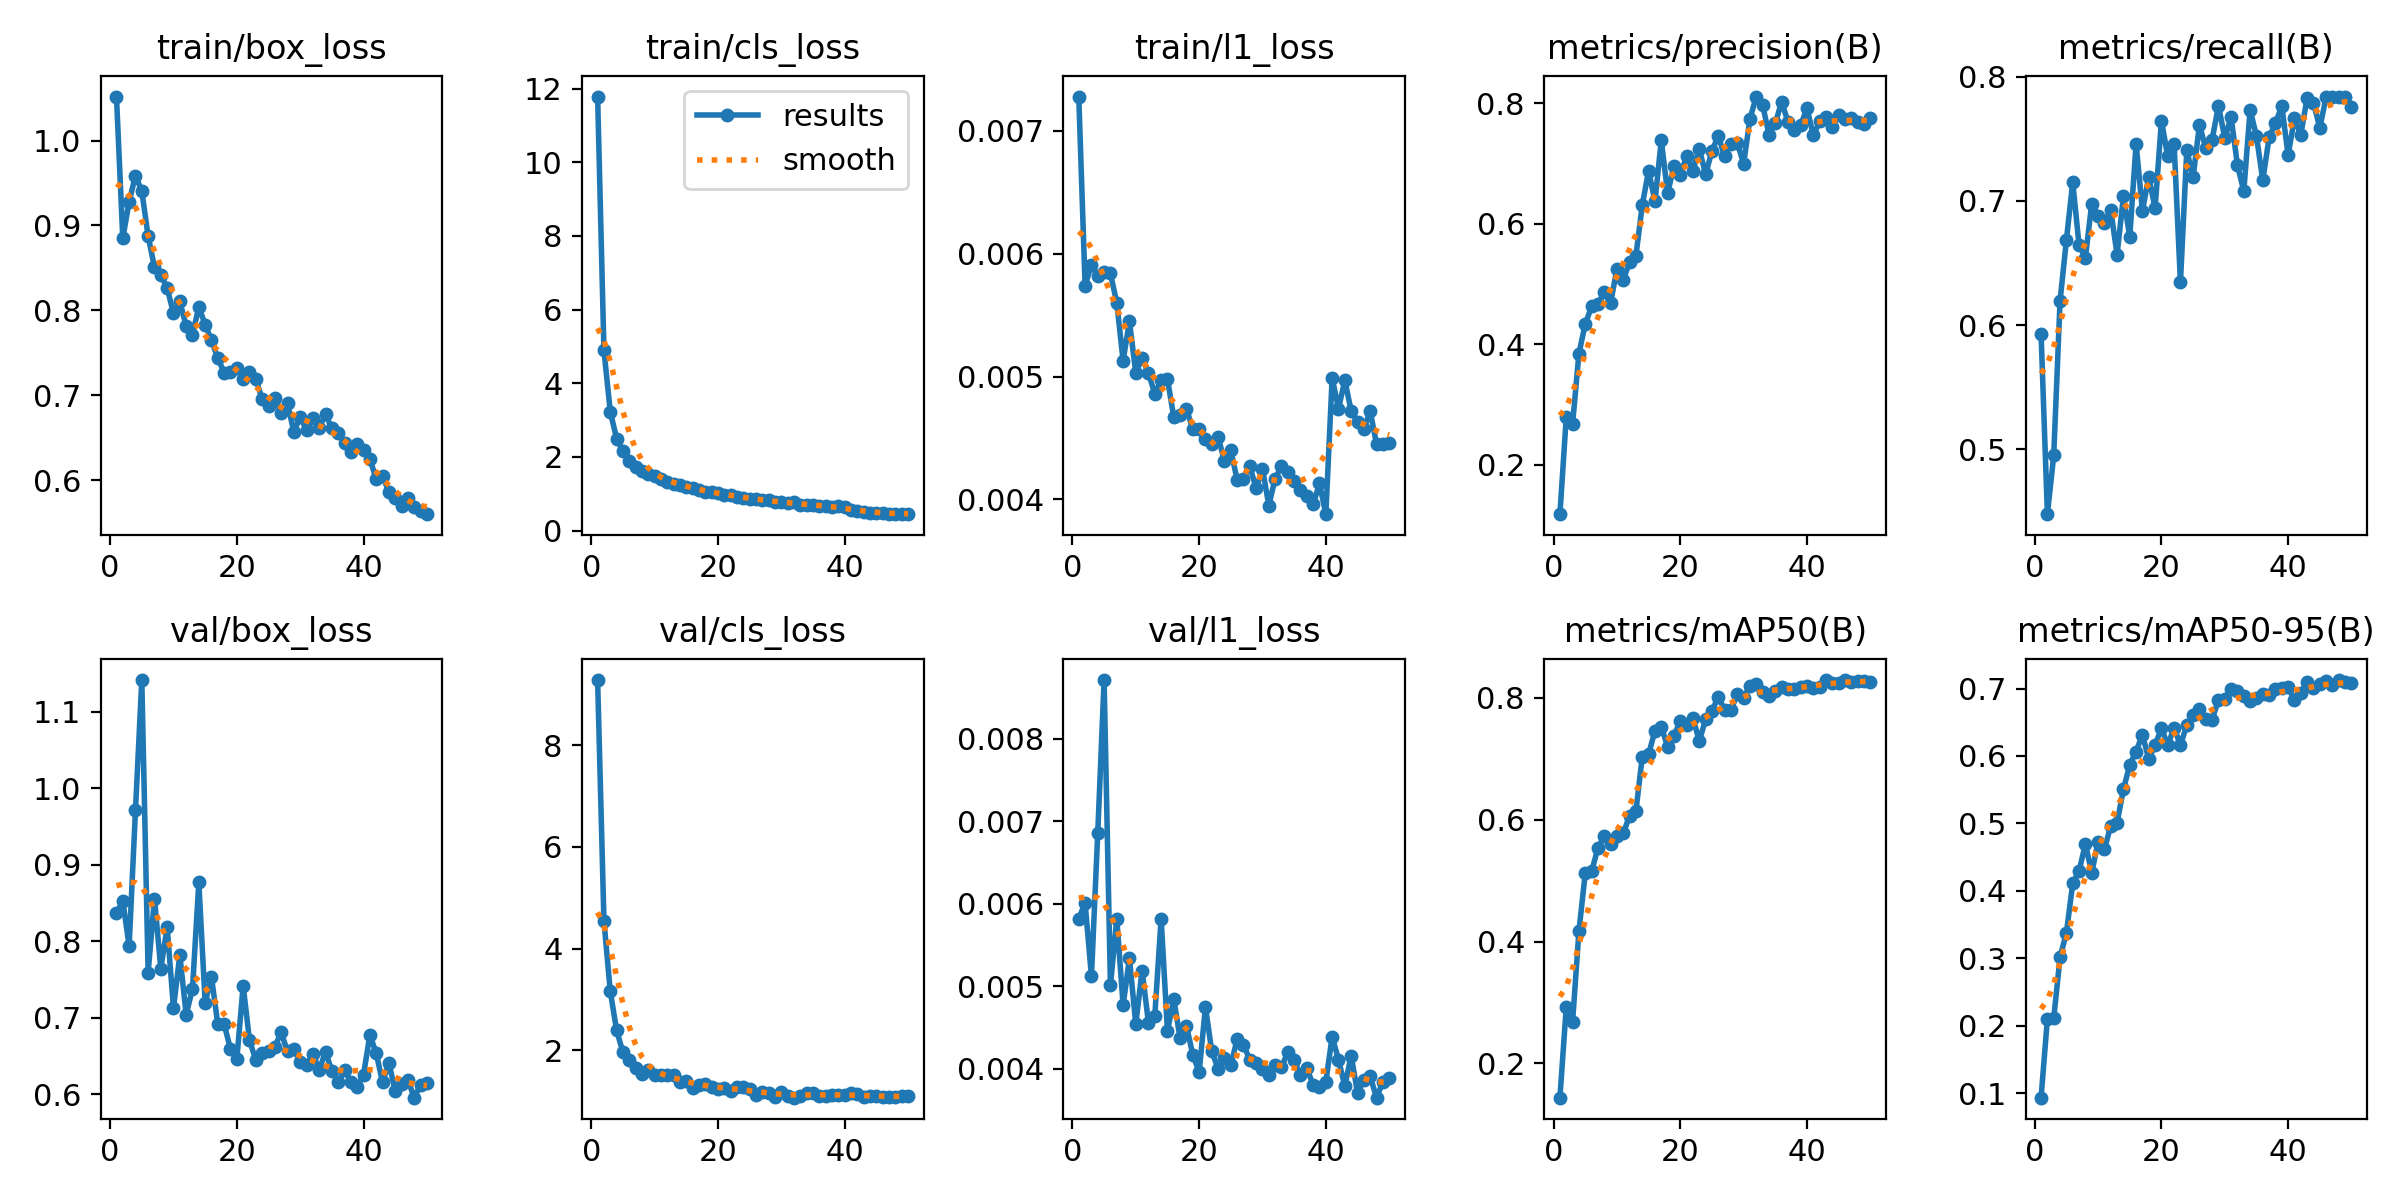

In [4]:
from IPython.display import Image, display

display(Image(filename=run / "results.png", width=900))

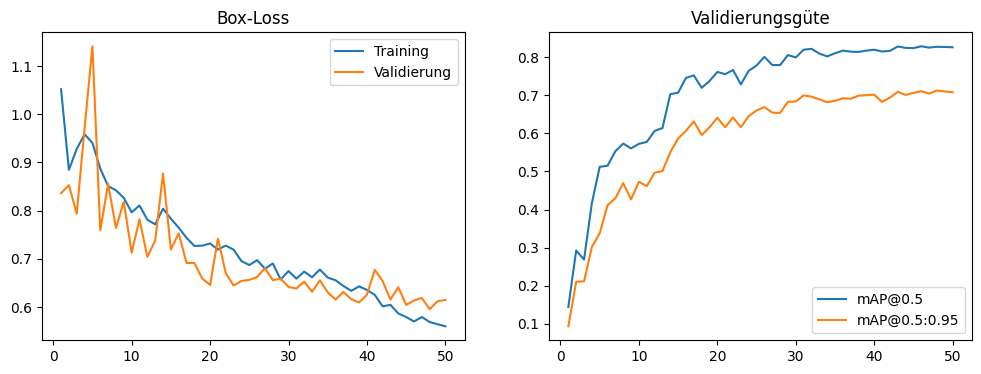

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv(run / "results.csv")
history.columns = history.columns.str.strip()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.epoch, history["train/box_loss"], label="Training")
ax[0].plot(history.epoch, history["val/box_loss"], label="Validierung")
ax[0].set_title("Box-Loss")
ax[0].legend()
ax[1].plot(history.epoch, history["metrics/mAP50(B)"], label="mAP@0.5")
ax[1].plot(history.epoch, history["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
ax[1].set_title("Validierungsgüte")
ax[1].legend()
plt.show()

## Was hat das Modell gesehen?

`labels.jpg` zeigt Klassenverteilung und Boxgrößen, `train_batch0.jpg` ein Trainingsbatch mit Mosaic-Augmentierung.

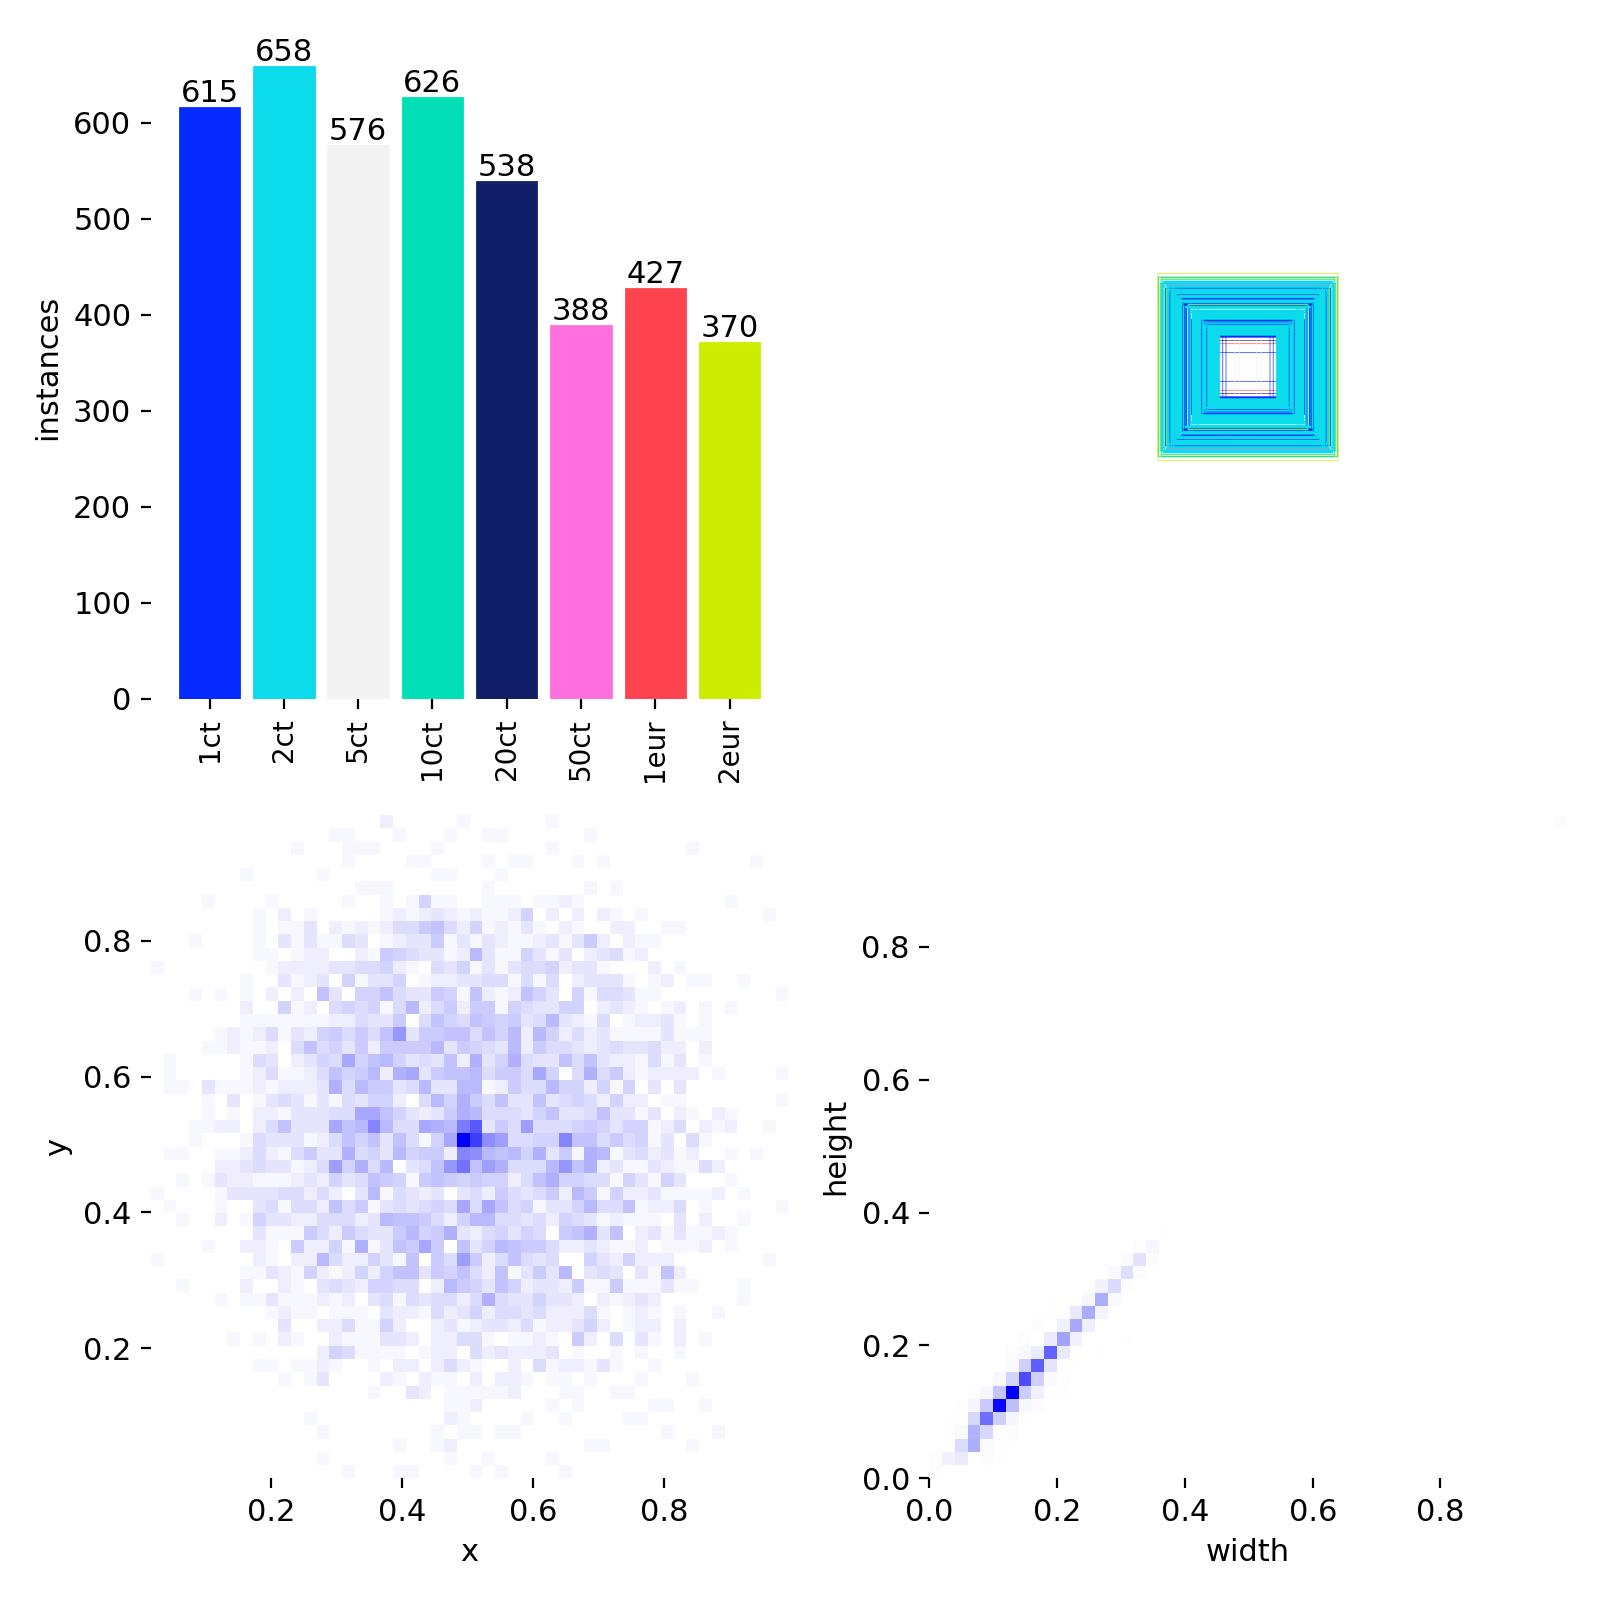

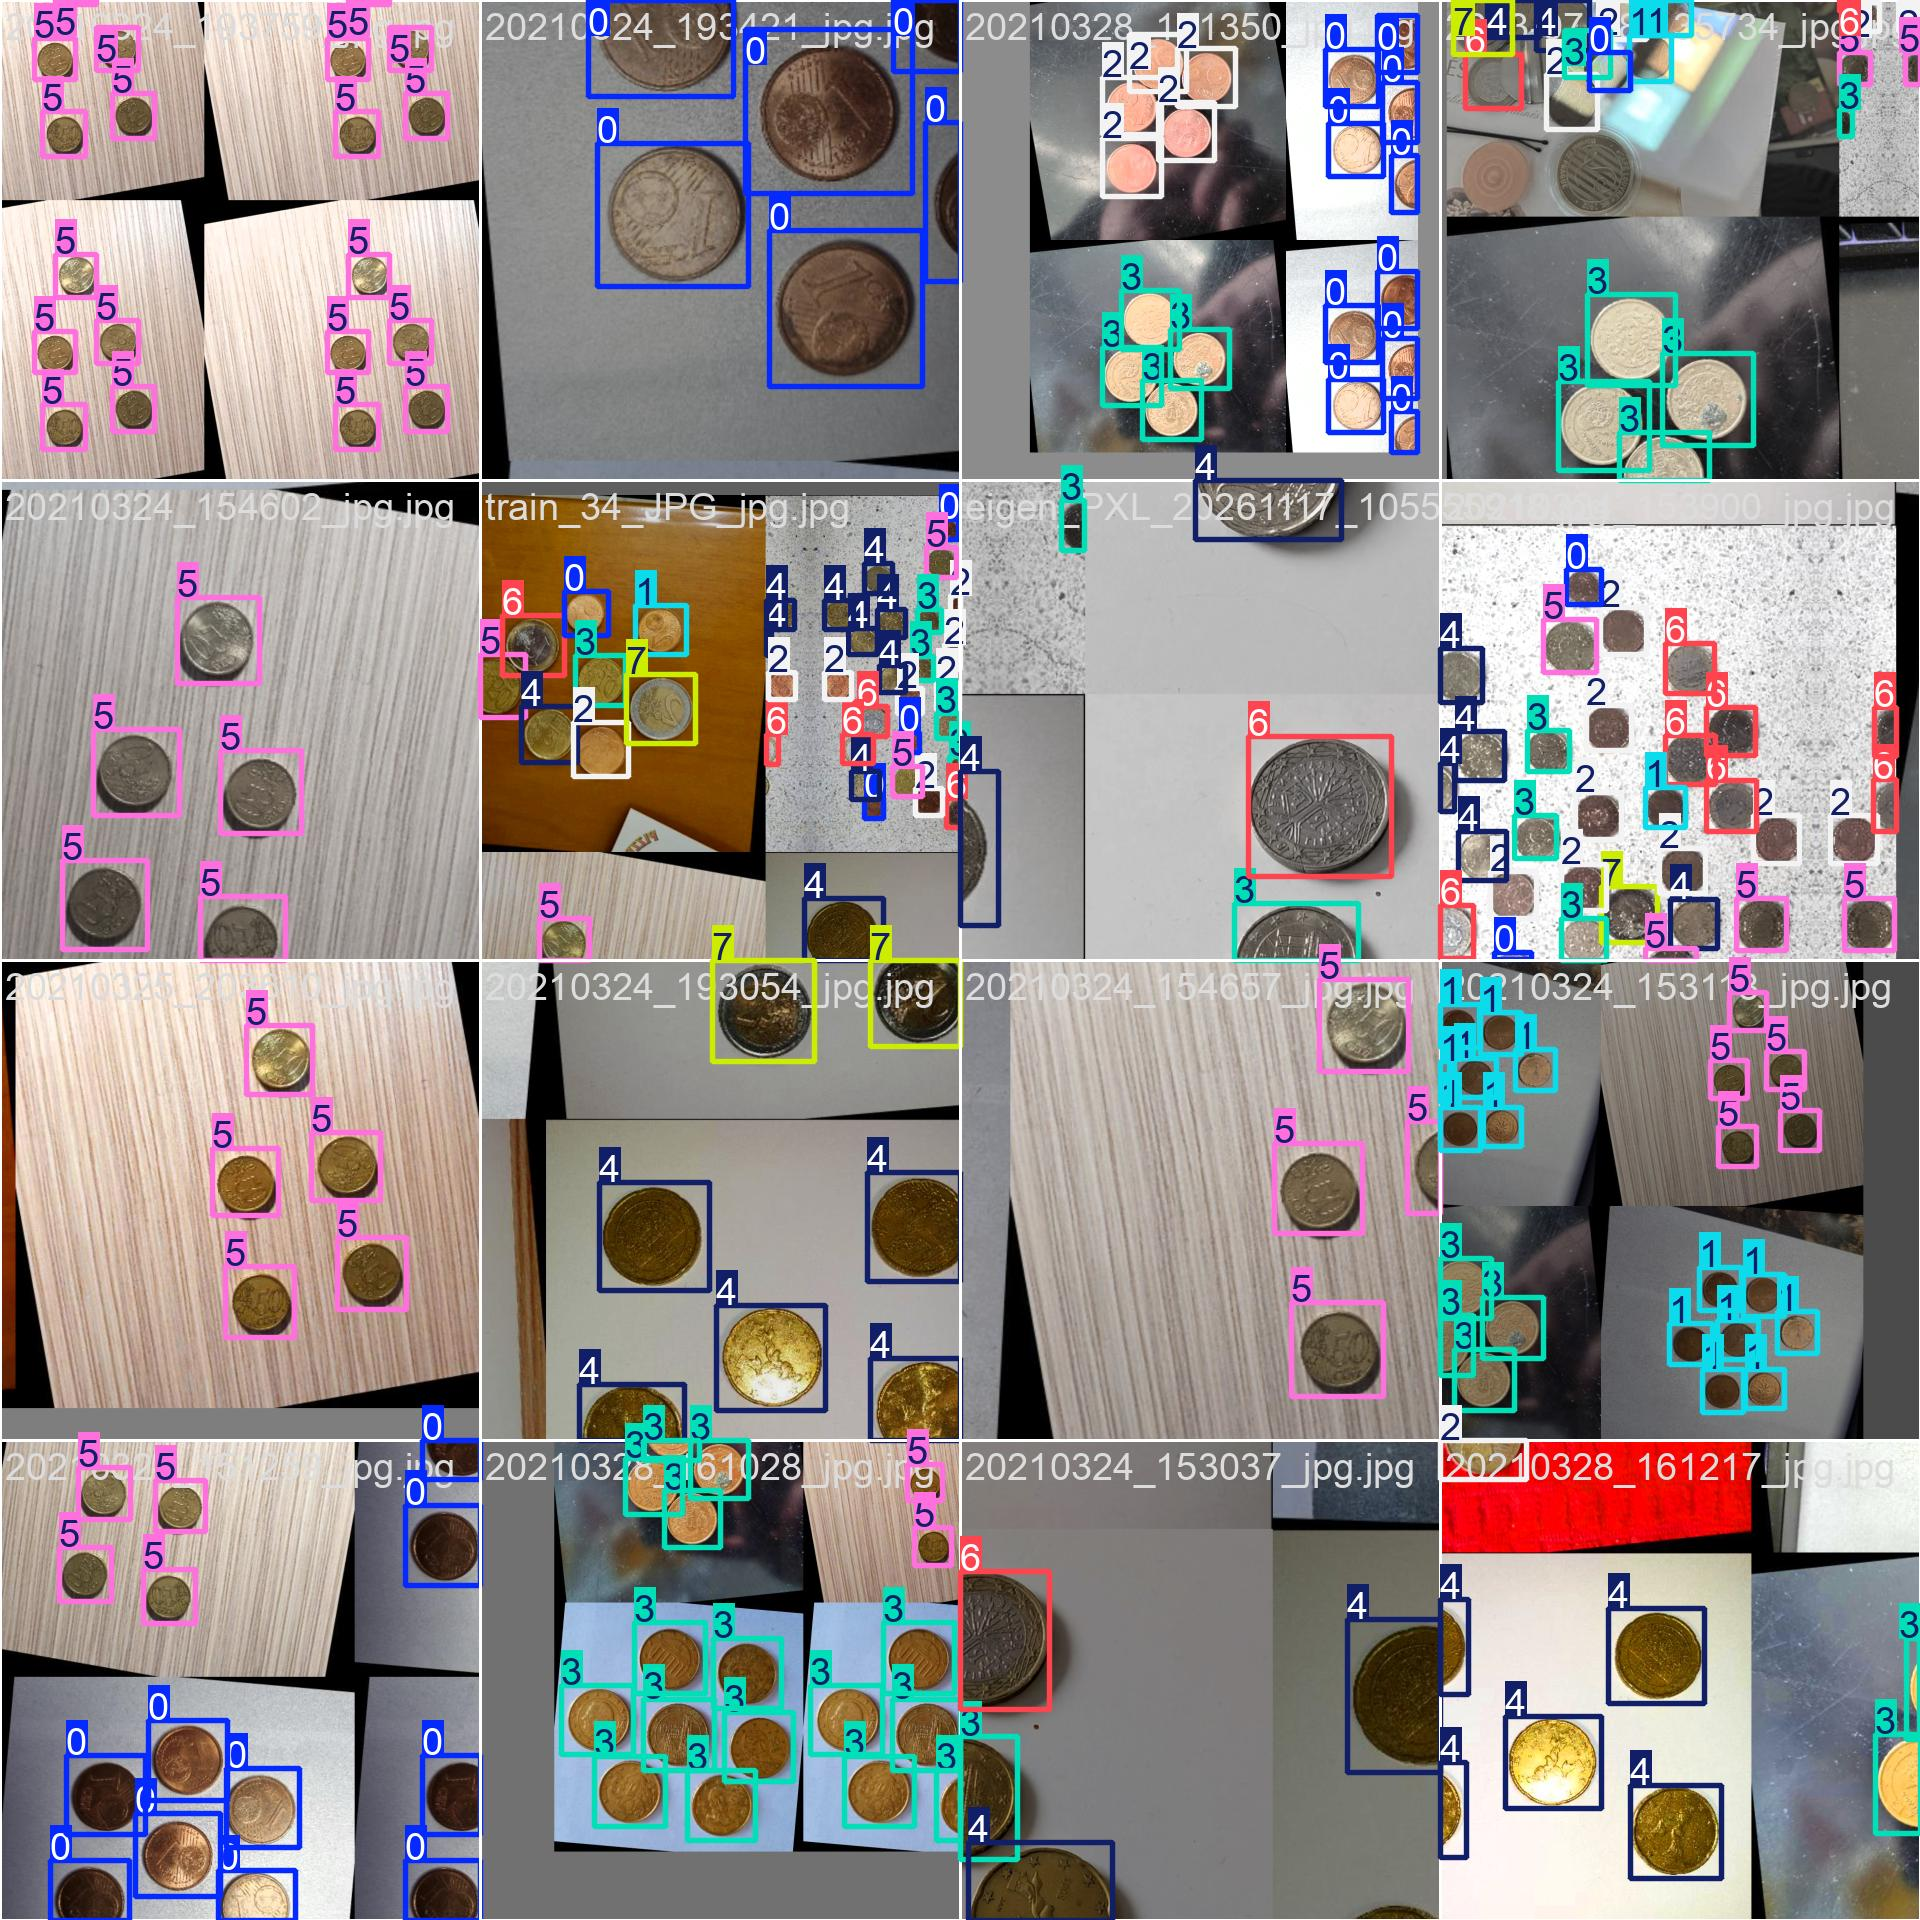

In [6]:
display(Image(filename=run / "labels.jpg", width=600))
display(Image(filename=run / "train_batch0.jpg", width=600))

## Das beste Modell verwenden

`best.pt` ist das Modell mit der besten Validierungsgüte, `last.pt` der letzte Stand, z. B. zum Fortsetzen mit `resume=True`. Wir wenden es auf `testbild.jpg` an.

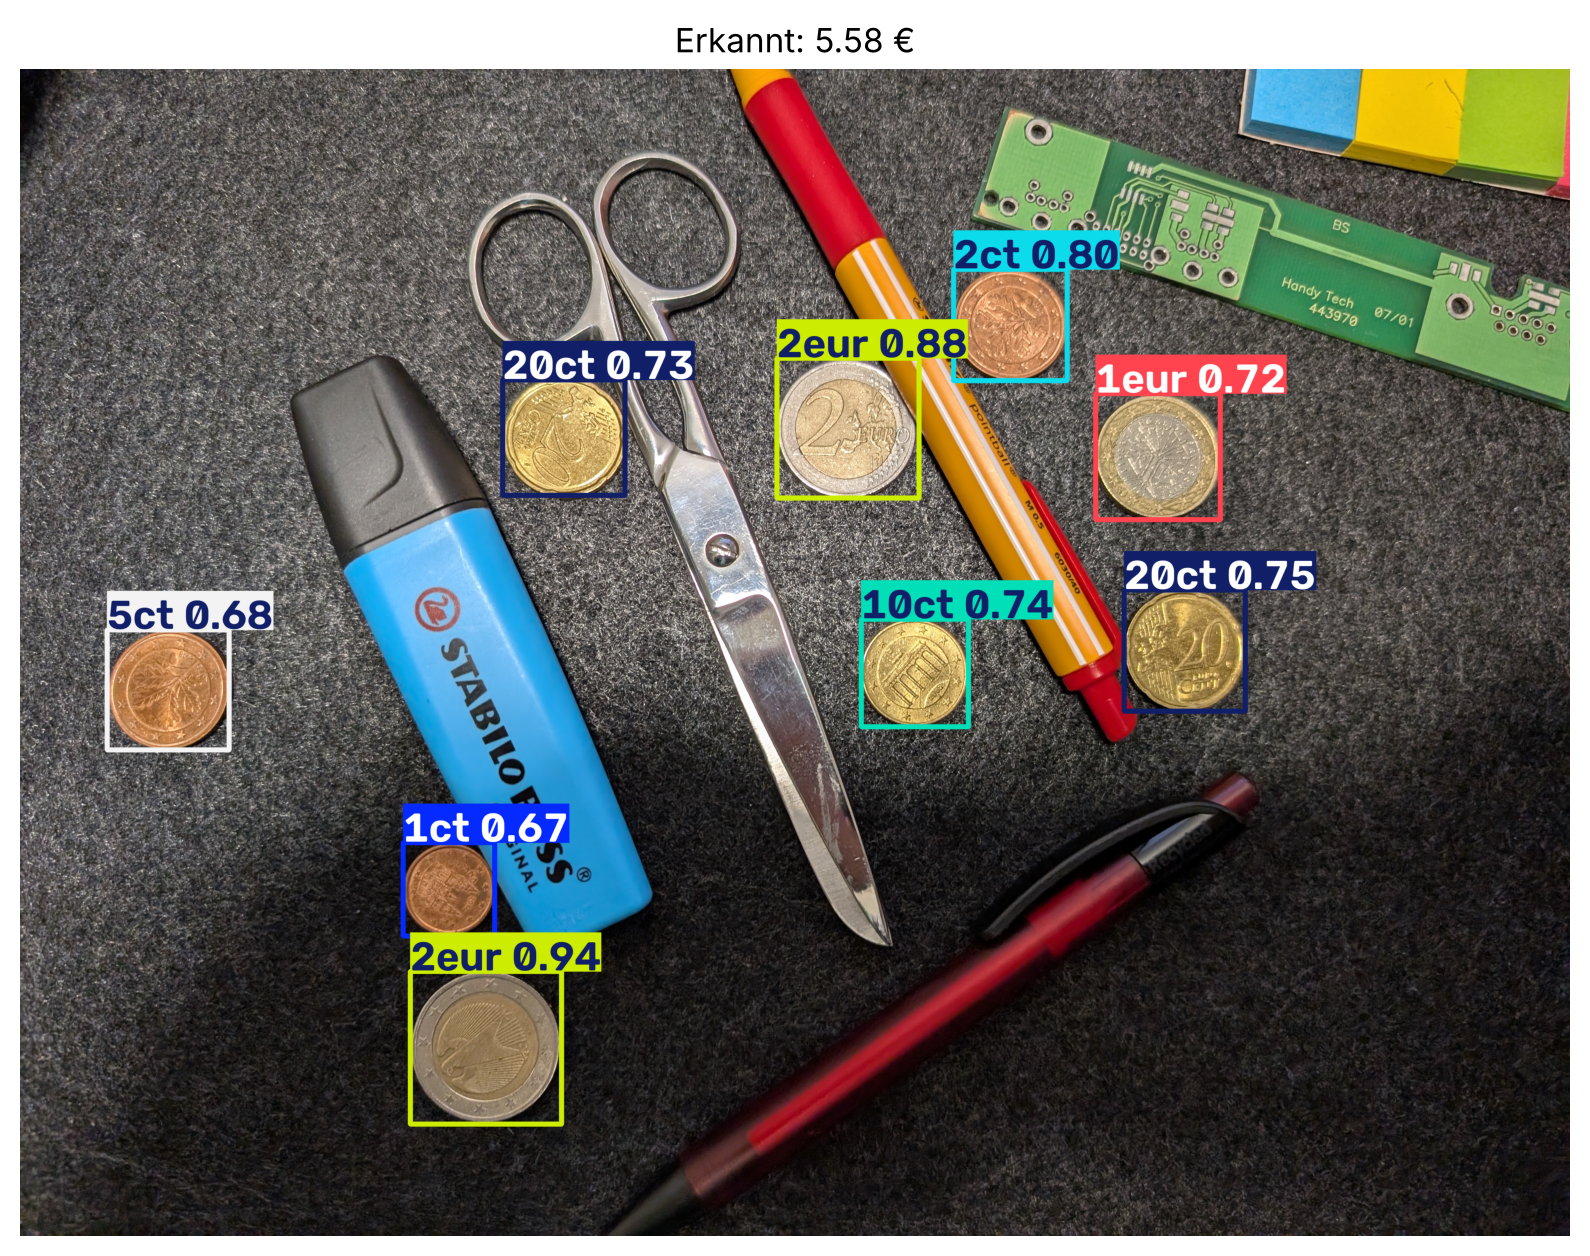

In [2]:
import cv2

VALUES = {"1ct": 0.01, "2ct": 0.02, "5ct": 0.05, "10ct": 0.10,
          "20ct": 0.20, "50ct": 0.50, "1eur": 1.00, "2eur": 2.00}

best = YOLO(run / "weights" / "best.pt")
r = best.predict("testbild.jpg", conf=0.5, agnostic_nms=True, verbose=False)[0]
total = sum(VALUES[r.names[int(c)]] for c in r.boxes.cls)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
plt.title(f"Erkannt: {total:.2f} €")
plt.axis("off")
plt.show()

## Optional: Transfer Learning gegen Training von Null

`yolo26n.yaml` enthält nur die Architektur ohne Gewichte. Vergleichen Sie bei gleicher Epochenzahl die erreichte mAP.

Mit `freeze=10` werden die ersten 10 Schichten (der Backbone) eingefroren. Das spart Rechenzeit, kann bei Münzen aber die Güte senken, weil sich die Bilder stark von COCO unterscheiden.

In [8]:
# scratch = YOLO("yolo26n.yaml").train(data=DATA, epochs=EPOCHS, name="muenzen_scratch")
# frozen = YOLO("yolo26n.pt").train(data=DATA, epochs=EPOCHS, freeze=10, name="muenzen_freeze")